In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df =pd.read_csv('RetailCleaned.csv', header=None)
df.columns = ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'CustomerID', 'Country', 'SourceSheet']

/tmp/ipykernel_1097/3083592652.py:1: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df =pd.read_csv('RetailCleaned.csv', header=None)


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1033036 entries, 0 to 1033035
Data columns (total 9 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      1033036 non-null  object 
 1   StockCode    1033036 non-null  object 
 2   Description  1028761 non-null  object 
 3   Quantity     1033036 non-null  int64  
 4   InvoiceDate  1033036 non-null  object 
 5   Price        1033036 non-null  float64
 6   CustomerID   797885 non-null   float64
 7   Country      1033036 non-null  object 
 8   SourceSheet  1033036 non-null  object 
dtypes: float64(2), int64(1), object(6)
memory usage: 70.9+ MB


In [ ]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df.shape

(1033036, 9)

In [ ]:
df.describe()

,Quantity,InvoiceDate,Price,CustomerID
count,1.033036e+06,1033036,1.033036e+06,797885.000000
mean,1.007688e+01,2011-01-03 14:30:35.429549056,4.613980e+00,15313.062777
min,-8.099500e+04,2009-12-01 07:45:00,-5.359436e+04,12346.000000
25%,1.000000e+00,2010-07-05 11:38:00,1.250000e+00,13964.000000
50%,3.000000e+00,2010-12-09 13:34:00,2.100000e+00,15228.000000
75%,1.000000e+01,2011-07-27 13:17:00,4.150000e+00,16788.000000
max,8.099500e+04,2011-12-09 12:50:00,3.897000e+04,18287.000000
std,1.751976e+02,NaN,1.223975e+02,1696.466663


In [ ]:
# Get numerical columns
numerical_cols = df.select_dtypes(include="number").columns

# Get categorical columns
categorical_cols = df.select_dtypes(include="object").columns

print("Numerical Columns:")
print(numerical_cols)

print("\nCategorical Columns:")
print(categorical_cols)

Numerical Columns:
Index(['Quantity', 'Price', 'CustomerID'], dtype='object')

Categorical Columns:
Index(['Invoice', 'StockCode', 'Description', 'Country', 'SourceSheet'], dtype='object')


In [ ]:
missing_values = df.isnull().sum()
missing_values

,0
Invoice,0
StockCode,0
Description,4275
Quantity,0
InvoiceDate,0
Price,0
CustomerID,235151
Country,0
SourceSheet,0


In [ ]:
# Check duplicate rows
duplicates = df.duplicated().sum()

print("Duplicate Rows:", duplicates)

Duplicate Rows: 0


In [ ]:
df["Description"] = df["Description"].fillna("Unknown")
df['Description'].isnull().sum()
df['CustomerID'].isnull().sum()

np.int64(235151)

In [ ]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country,SourceSheet
0,552954,84755,COLOUR GLASS T-LIGHT HOLDER HANGING,16,2011-05-12 12:30:00,0.65,14064.0,United Kingdom,2009-2010
1,552954,84970S,HANGING HEART ZINC T-LIGHT HOLDER,12,2011-05-12 12:30:00,0.85,14064.0,United Kingdom,2009-2010
2,552954,85123A,WHITE HANGING HEART T-LIGHT HOLDER,32,2011-05-12 12:30:00,2.55,14064.0,United Kingdom,2009-2010
3,552955,15058A,BLUE POLKADOT GARDEN PARASOL,10,2011-05-12 12:30:00,6.75,13113.0,United Kingdom,2009-2010
4,552955,22088,PAPER BUNTING COLOURED LACE,4,2011-05-12 12:30:00,2.95,13113.0,United Kingdom,2009-2010


In [ ]:
df['Total_revenue'] = df['Price'] * df['Quantity']
df

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country,SourceSheet,Total_revenue
0,552954,84755,COLOUR GLASS T-LIGHT HOLDER HANGING,16,2011-05-12 12:30:00,0.65,14064.0,United Kingdom,2009-2010,10.40
1,552954,84970S,HANGING HEART ZINC T-LIGHT HOLDER,12,2011-05-12 12:30:00,0.85,14064.0,United Kingdom,2009-2010,10.20
2,552954,85123A,WHITE HANGING HEART T-LIGHT HOLDER,32,2011-05-12 12:30:00,2.55,14064.0,United Kingdom,2009-2010,81.60
3,552955,15058A,BLUE POLKADOT GARDEN PARASOL,10,2011-05-12 12:30:00,6.75,13113.0,United Kingdom,2009-2010,67.50
4,552955,22088,PAPER BUNTING COLOURED LACE,4,2011-05-12 12:30:00,2.95,13113.0,United Kingdom,2009-2010,11.80
...,...,...,...,...,...,...,...,...,...,...
1033031,552954,22178,VICTORIAN GLASS HANGING T-LIGHT,96,2011-05-12 12:30:00,1.06,14064.0,United Kingdom,2009-2010,101.76
1033032,552954,22296,HEART IVORY TRELLIS LARGE,24,2011-05-12 12:30:00,1.65,14064.0,United Kingdom,2009-2010,39.60
1033033,552954,22585,PACK OF 6 BIRDY GIFT TAGS,6,2011-05-12 12:30:00,1.25,14064.0,United Kingdom,2009-2010,7.50
1033034,552954,22948,METAL DECORATION NAUGHTY CHILDREN,12,2011-05-12 12:30:00,0.85,14064.0,United Kingdom,2009-2010,10.20


In [ ]:
top_10_revenue = df.sort_values(by='Total_revenue', ascending=False).head(10)
top_10_revenue

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country,SourceSheet,Total_revenue
343657,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom,2009-2010,168469.60
910757,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346.0,United Kingdom,2009-2010,77183.60
34575,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,2011-06-10 15:28:00,649.50,15098.0,United Kingdom,2009-2010,38970.00
597959,512771,M,Manual,1,2010-06-17 16:53:00,25111.09,NaN,United Kingdom,2010-2011,25111.09
782344,530715,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,9360,2010-11-04 11:36:00,1.69,15838.0,United Kingdom,2010-2011,15818.40
865359,537632,AMAZONFEE,AMAZON FEE,1,2010-12-07 15:08:00,13541.33,NaN,United Kingdom,2009-2010,13541.33
345135,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,11062.06,NaN,United Kingdom,2009-2010,11062.06
494910,502265,M,Manual,1,2010-03-23 15:28:00,10953.50,NaN,United Kingdom,2010-2011,10953.50
494909,502263,M,Manual,1,2010-03-23 15:22:00,10953.50,12918.0,United Kingdom,2010-2011,10953.50
724985,525399,M,Manual,1,2010-10-05 11:49:00,10468.80,NaN,United Kingdom,2010-2011,10468.80


In [ ]:
# Group by CustomerID and sum their total revenue
customer_revenue = df.groupby('CustomerID')['Total_revenue'].sum().reset_index()

# Sort customers by their total revenue contribution
customer_revenue = customer_revenue.sort_values(by='Total_revenue', ascending=False)

# Calculate overall total revenue across all customers
total_net_revenue = customer_revenue['Total_revenue'].sum()

# Determine the number of customers that make up the top 10%
num_top_10_percent = int(np.ceil(0.10 * len(customer_revenue)))

# Calculate the revenue of the top 10% of customers
top_10_percent_revenue = customer_revenue.head(num_top_10_percent)['Total_revenue'].sum()

# Percentage calculation
pct_revenue_top_10 = (top_10_percent_revenue / total_net_revenue) * 100

print(f"Total Customers: {len(customer_revenue)}")
print(f"Number of Customers in Top 10%: {num_top_10_percent}")
print(f"Total Revenue from Top 10% of Customers: ${top_10_percent_revenue:,.2f}")
print(f"Overall Total Revenue: ${total_net_revenue:,.2f}")
print(f"Percentage of Total Revenue from Top 10% of Customers: {pct_revenue_top_10:.2f}%")

Total Customers: 5942
Number of Customers in Top 10%: 595
Total Revenue from Top 10% of Customers: $10,380,706.59
Overall Total Revenue: $16,289,991.27
Percentage of Total Revenue from Top 10% of Customers: 63.72%


In [ ]:


# Group by CustomerID to calculate frequency (unique Invoice count) and total revenue
customer_stats = df.groupby('CustomerID').agg(
    Frequency=('Invoice', 'nunique'),
    Total_Revenue=('Total_revenue', 'sum')
).reset_index()

# Filter out 'Null' customer IDs or negative/zero revenues for cleaner visualization
clean_stats = customer_stats[(customer_stats['CustomerID'] != 'Null') & (customer_stats['Total_Revenue'] > 0)]

# Define thresholds for 'high frequency' and 'low revenue' dynamically (e.g., using percentiles)
freq_threshold = clean_stats['Frequency'].quantile(0.75) # Top 25% in purchase frequency
rev_threshold = clean_stats['Total_Revenue'].quantile(0.50) # Bottom 50% in revenue contribution

# Identify these specific customers
high_freq_low_rev = clean_stats[(clean_stats['Frequency'] >= freq_threshold) & (clean_stats['Total_Revenue'] <= rev_threshold)]

print(f"Number of customers with high frequency (>= {freq_threshold:.0f} orders) but low revenue (<= ${rev_threshold:,.2f}): {len(high_freq_low_rev)}")
display(high_freq_low_rev.sort_values(by='Frequency', ascending=False).head(10))

Number of customers with high frequency (>= 8 orders) but low revenue (<= $846.62): 38


,CustomerID,Frequency,Total_Revenue
5691,18037.0,15,167.42
5642,17988.0,15,479.59
545,12891.0,12,819.50
2761,15107.0,12,740.26
2566,14912.0,11,748.58
5257,17603.0,11,114.91
2958,15304.0,11,782.30
4016,16362.0,11,816.96
4154,16500.0,10,835.96
4209,16555.0,10,285.89


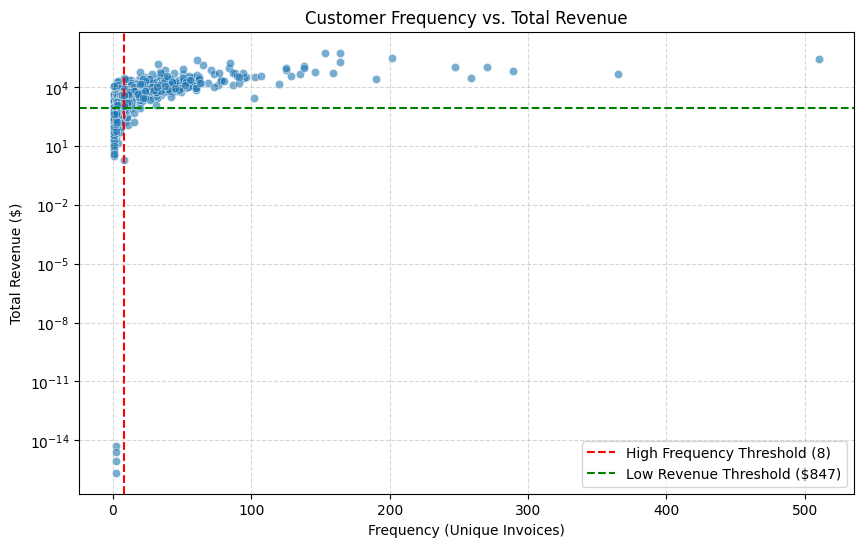

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=clean_stats, x='Frequency', y='Total_Revenue', alpha=0.6)
plt.axvline(x=freq_threshold, color='r', linestyle='--', label=f'High Frequency Threshold ({freq_threshold:.0f})')
plt.axhline(y=rev_threshold, color='g', linestyle='--', label=f'Low Revenue Threshold (${rev_threshold:,.0f})')
plt.title('Customer Frequency vs. Total Revenue')
plt.xlabel('Frequency (Unique Invoices)')
plt.ylabel('Total Revenue ($)')
plt.yscale('log') # Log scale to better visualize wide revenue ranges
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.show()

In [ ]:
# Define thresholds for 'low frequency' and 'high revenue'
# Median frequency (50th percentile or lower)
low_freq_threshold = clean_stats['Frequency'].quantile(0.50)
# Top 25% in total revenue contribution
high_rev_threshold = clean_stats['Total_Revenue'].quantile(0.75)

# Filter for customers meeting both criteria
low_freq_high_rev = clean_stats[
    (clean_stats['Frequency'] <= low_freq_threshold) &
    (clean_stats['Total_Revenue'] >= high_rev_threshold)
]

print(f"Number of customers with low frequency (<= {low_freq_threshold:.0f} orders) but high revenue (>= ${high_rev_threshold:,.2f}): {len(low_freq_high_rev)}")
display(low_freq_high_rev.sort_values(by='Total_Revenue', ascending=False).head(10))

Number of customers with low frequency (<= 4 orders) but high revenue (>= $2,180.28): 76


,CustomerID,Frequency,Total_Revenue
3403,15749.0,4,21535.90
11,12357.0,3,18287.66
3654,16000.0,3,12393.70
1341,13687.0,1,11880.84
5706,18052.0,1,10877.18
1745,14091.0,2,9530.08
452,12798.0,4,8510.93
151,12497.0,4,6211.75
1589,13935.0,3,6116.92
32,12378.0,2,5416.32


In [ ]:
#Filter and Calculate Recency, Frequency and Monetary
rfm_data = df[(df['CustomerID'].notna()) & (df['Quantity'] > 0)].copy()
snapshot_date = pd.to_datetime('2011-12-10')

rfm = rfm_data.groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda x: (snapshot_date - x.max()).days),
    Frequency=('Invoice', 'nunique'),
    Monetary=('Total_revenue', 'sum')
).reset_index()

rfm.head()

,CustomerID,Recency,Frequency,Monetary
0,12346.0,325,12,77556.46
1,12347.0,2,8,4921.53
2,12348.0,75,5,2019.40
3,12349.0,18,4,4428.69
4,12350.0,310,1,334.40


In [ ]:
rfm['R_Score'] = pd.qcut(rfm['Recency'], 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm['M_Score'] = pd.qcut(rfm['Monetary'], 5, labels=[1, 2, 3, 4, 5]).astype(int)

def customer_segment(row):
  if row['R_Score']>=4 and row['F_Score']>=4 and row['M_Score']>=4:
    return 'Champions'
  elif row['R_Score']>=3 and row['F_Score']>=3:
    return 'Loyal'
  elif row['R_Score']<=2 and row['F_Score']>=3:
    return 'At Risk'
  elif row['R_Score']>=4 and row['F_Score']<=2:
    return 'New'
  elif row['R_Score'] == 3 and row['F_Score']<=2:
    return 'Needs Attention'
  else:
    return 'Lost'

rfm['segment'] = rfm.apply(customer_segment, axis=1)
rfm['IsChurned'] = rfm['Recency']>90

In [ ]:
#Merge RFM results back onto transactions and export
df = df[(df['CustomerID'].notna()) & (df['Quantity']>0)].copy()
df['InvoiceMonth'] = df['InvoiceDate'].dt.to_period('M').dt.to_timestamp()
df['Revenue'] = df['Quantity'] * df['Price']

df_final = df.merge(
    rfm[['CustomerID', 'Recency', 'Frequency', 'Monetary', 'R_Score', 'F_Score', 'M_Score', 'segment', 'IsChurned']],
    on='CustomerID',
    how='left'
)
df_final.to_excel('EcommerceDashboardData.xlsx', index=False)